In [1]:
# ENTORNO Y PARÁMETROS (EMG del gastrocnemio)

import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.stats import kurtosis, skew

# Solo se silencian los RuntimeWarning
warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(42)

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLOR_REPOSO, COLOR_CONTRAC, COLOR_UPCH = "#4C72B0", "#C44E52", "#7F000E"

try:
    from IPython.display import display
except ImportError:
    display = print

print("Entorno listo.")

Entorno listo.


In [2]:
# LECTURA DE LOS REGISTROS
# Baseline = gastrocnemio en reposo | Prueba = gastrocnemio con fuerza contraria
def leer_opensignals(ruta, etiqueta_canal="A1"):
    # Lee el TXT de OpenSignals: devuelve los valores ADC del canal y los metadatos de la cabecera
    with open(ruta, "r", encoding="utf-8") as f:
        cabecera = [next(f) for _ in range(3)]
    meta = list(json.loads(cabecera[1].lstrip("# ").strip()).values())[0]
    datos = np.loadtxt(ruta, comments="#")
    idx_col = meta["column"].index(etiqueta_canal)
    idx_res = meta["column"].index(etiqueta_canal)
    meta["bits"] = meta["resolution"][idx_res]
    return datos[:, idx_col].astype(float), meta


def simular_registros(fs=1000, n_bits=10):
    # Respaldo: crea un baseline y una prueba simulados (contracciones cada ~3 s, en cuentas ADC)
    rng = np.random.default_rng(0)
    def a_adc(mv):
        adc = (mv / 1000 * 1009 / 3.3 + 0.5) * 2**n_bits
        return np.clip(np.round(adc), 0, 2**n_bits - 1)
    base = 0.006 * rng.standard_normal(69 * fs)
    t = np.arange(63 * fs) / fs
    prueba = 0.025 * rng.standard_normal(len(t))
    for k, ini in enumerate(np.arange(1.5, 61, 3.0)):
        idx = (t >= ini) & (t < ini + 1.2)
        env = np.hanning(idx.sum())
        b, a = signal.butter(2, [40, 200], "bandpass", fs=fs)
        ruido = signal.lfilter(b, a, rng.standard_normal(idx.sum()))
        prueba[idx] += (0.9 - 0.01 * k) * env * ruido / ruido.std() * 0.5
    meta = {"sampling rate": fs, "bits": n_bits, "sensor": ["EMG simulado"], "date": "-", "time": "-"}
    return a_adc(base), dict(meta), a_adc(prueba), dict(meta)


adc_base, meta_base = leer_opensignals("gastrocnemio_reposo.txt")
adc_prueba, meta_prueba = leer_opensignals("gastrocnemio_f_contrario.txt")

FS = int(meta_prueba["sampling rate"])
N_BITS = int(meta_prueba["bits"])
assert FS == int(meta_base["sampling rate"]), "Los registros tienen Fs distintas."

for nombre, adc, meta in [("BASELINE", adc_base, meta_base), ("PRUEBA", adc_prueba, meta_prueba)]:
    print(f"{nombre:9s} | sensor: {meta['sensor'][0]:11s} | fecha: {meta['date']} {meta['time']} | "
          f"Fs = {meta['sampling rate']} Hz | {meta['bits']} bits | "
          f"{len(adc):,} muestras = {len(adc)/FS:.1f} s | ADC min/max: {adc.min():.0f}/{adc.max():.0f}")

BASELINE  | sensor: EMGBITREV   | fecha: 2026-9-4 15:11:0.213 | Fs = 1000 Hz | 10 bits | 32,400 muestras = 32.4 s | ADC min/max: 506/519
PRUEBA    | sensor: EMGBITREV   | fecha: 2026-9-4 15:35:19.797 | Fs = 1000 Hz | 10 bits | 30,750 muestras = 30.8 s | ADC min/max: 374/694


Rango medible del sensor: ±1.632 mV
Resolución (1 cuenta ADC): 0.0032 mV = 3.19 µV


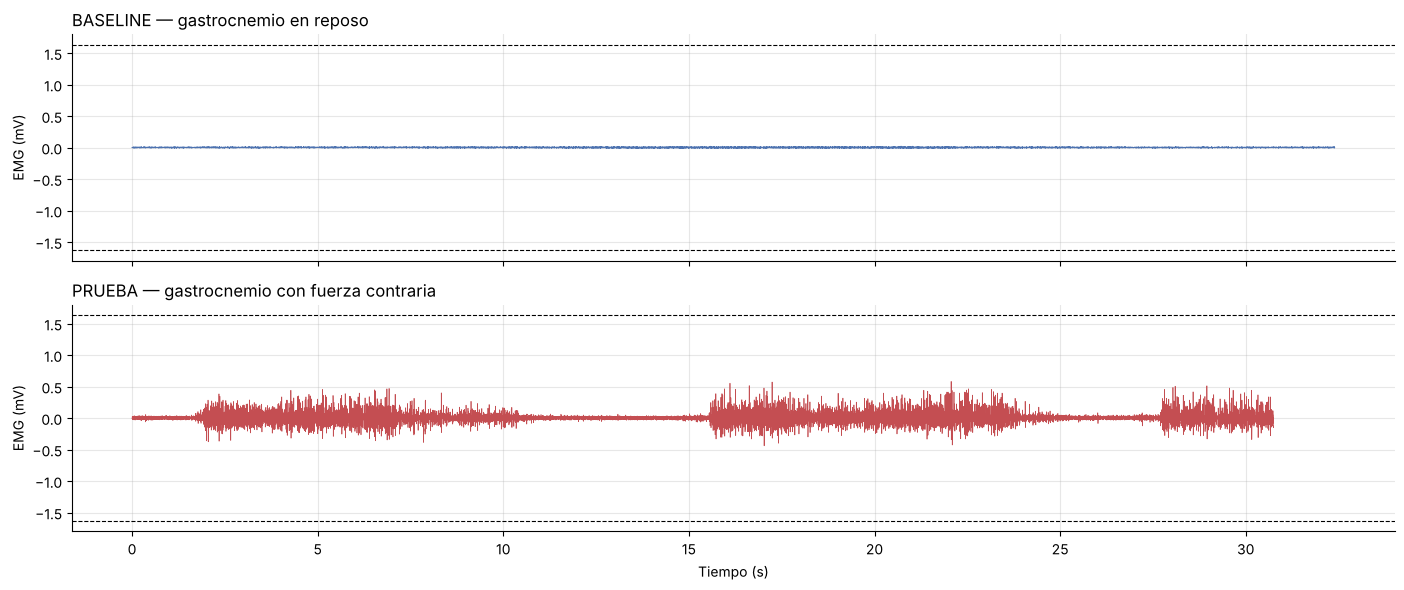

In [3]:
VCC, G_EMG = 3.3, 1009

# CONVERSIÓN DE CUENTAS ADC A mV Y RANGO DEL SENSOR

def adc_a_mV(adc, n_bits=N_BITS, vcc=VCC, ganancia=G_EMG):
    return ((adc / 2**n_bits) - 0.5) * vcc / ganancia * 1000

emg_base_mV   = adc_a_mV(adc_base)
emg_prueba_mV = adc_a_mV(adc_prueba)
t_base   = np.arange(len(emg_base_mV)) / FS
t_prueba = np.arange(len(emg_prueba_mV)) / FS

rango_max = adc_a_mV(2**N_BITS - 1)
print(f"Rango medible del sensor: ±{rango_max:.3f} mV")
print(f"Resolución (1 cuenta ADC): {adc_a_mV(513) - adc_a_mV(512):.4f} mV = "
      f"{(adc_a_mV(513) - adc_a_mV(512))*1000:.2f} µV")

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
ax[0].plot(t_base, emg_base_mV, lw=0.5, color=COLOR_REPOSO)
ax[0].set_title("BASELINE — gastrocnemio en reposo", loc="left")
ax[1].plot(t_prueba, emg_prueba_mV, lw=0.5, color=COLOR_CONTRAC)
ax[1].set_title("PRUEBA — gastrocnemio con fuerza contraria", loc="left")
for a in ax:
    a.axhline(rango_max, ls="--", color="k", lw=0.8); a.axhline(-rango_max, ls="--", color="k", lw=0.8)
    a.set_ylabel("EMG (mV)")
ax[1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

In [4]:
# SATURACIÓN DEL ADC
# Si una muestra vale 0 o 2^n-1, la señal superó el rango del ADC y quedó recortada (esa información no se recupera).

sat_prueba = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 1)
sat_base   = (adc_base   <= 0) | (adc_base   >= 2**N_BITS - 1)
print(f"Saturación BASELINE: {sat_base.sum()} muestras ({100*sat_base.mean():.3f} %)")
print(f"Saturación PRUEBA  : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")

if sat_prueba.any():
    i0 = np.flatnonzero(sat_prueba)[0]
    sl = slice(max(0, i0 - 150), i0 + 150)
    plt.figure(figsize=(12, 3))
    plt.plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.9, color=COLOR_CONTRAC)
    plt.plot(t_prueba[sl][sat_prueba[sl]], emg_prueba_mV[sl][sat_prueba[sl]], "ko", ms=3, label="saturada")
    plt.title("Zoom a un evento de saturación"); plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend()
    plt.show()

Saturación BASELINE: 0 muestras (0.000 %)
Saturación PRUEBA  : 0 muestras (0.000 %)


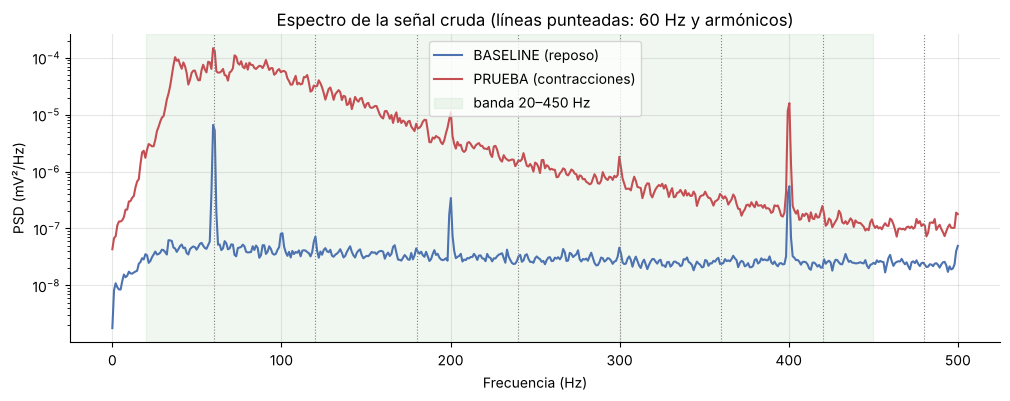

In [5]:
# ESPECTRO DE LA SEÑAL CRUDA (Welch)
# Welch promedia los periodogramas de varios segmentos → PSD más estable; antes se quita el offset DC.

def psd(x, fs=FS, nperseg=1024):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=nperseg)

f_b, P_b = psd(emg_base_mV)
f_p, P_p = psd(emg_prueba_mV)

plt.figure(figsize=(12, 4))
plt.semilogy(f_b, P_b, label="BASELINE (reposo)", color=COLOR_REPOSO)
plt.semilogy(f_p, P_p, label="PRUEBA (contracciones)", color=COLOR_CONTRAC)
for k in range(1, 9):
    plt.axvline(60*k, color="gray", ls=":", lw=0.8)
plt.axvspan(20, 450, color="green", alpha=0.06, label="banda 20–450 Hz")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD (mV²/Hz)")
plt.title("Espectro de la señal cruda (líneas punteadas: 60 Hz y armónicos)")
plt.legend(); plt.show()

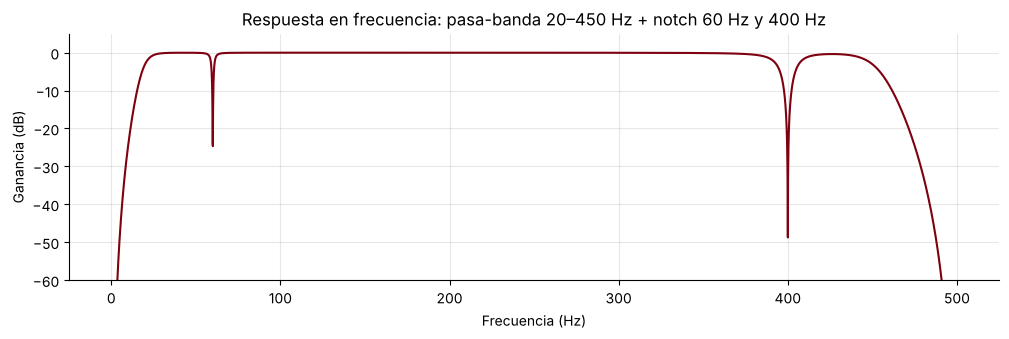

In [6]:
# FILTRADO: pasa-banda 20–450 Hz + notch en 60 Hz y 400 Hz

def filtrar_emg(x, fs=FS, f_baja=20, f_alta=450, orden=4, f_notches=[60, 400], q_notch=30):
    if not (0 < f_baja < f_alta < fs/2):
        raise ValueError(f"Se requiere 0 < f_baja < f_alta < Fs/2 (Fs = {fs} Hz).")

    sos = signal.butter(orden, [f_baja, f_alta], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))

    if f_notches:
        for fn in f_notches:
            b, a = signal.iirnotch(fn, q_notch, fs=fs)
            y = signal.filtfilt(b, a, y)

    return y

# Respuesta en frecuencia del filtro completo (mismos parámetros que filtrar_emg)
sos = signal.butter(4, [20, 450], btype="bandpass", fs=FS, output="sos")
w, h_total = signal.sosfreqz(sos, worN=4096, fs=FS)

for fn in [60, 400]:
    b_n, a_n = signal.iirnotch(fn, 30, fs=FS)
    _, h_n = signal.freqz(b_n, a_n, worN=4096, fs=FS)
    h_total *= h_n

plt.figure(figsize=(12, 3.2))
plt.plot(w, 20*np.log10(np.abs(h_total) + 1e-12), color=COLOR_UPCH)
plt.ylim(-60, 5)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Ganancia (dB)")
plt.title("Respuesta en frecuencia: pasa-banda 20–450 Hz + notch 60 Hz y 400 Hz")
plt.show()
emg_base_f   = filtrar_emg(emg_base_mV)
emg_prueba_f = filtrar_emg(emg_prueba_mV)

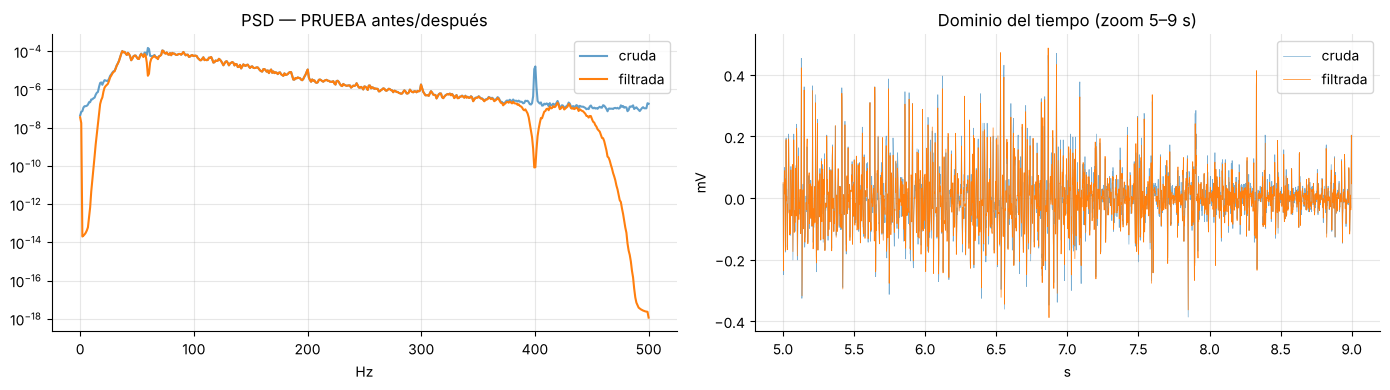

RMS del baseline filtrado (piso de ruido): 3.65 µV
RMS global de la prueba filtrada        : 78.97 µV
SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = 26.7 dB


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
f1, P1 = psd(emg_prueba_mV); f2, P2 = psd(emg_prueba_f)
ax[0].semilogy(f1, P1, label="cruda", alpha=0.7); ax[0].semilogy(f2, P2, label="filtrada")
ax[0].set_title("PSD — PRUEBA antes/después"); ax[0].set_xlabel("Hz"); ax[0].legend()

sl = (t_prueba > 5) & (t_prueba < 9)
ax[1].plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.5, alpha=0.6, label="cruda")
ax[1].plot(t_prueba[sl], emg_prueba_f[sl], lw=0.5, label="filtrada")
ax[1].set_title("Dominio del tiempo (zoom 5–9 s)"); ax[1].set_xlabel("s"); ax[1].set_ylabel("mV"); ax[1].legend()
plt.tight_layout(); plt.show()

# SNR aproximada: el baseline (reposo) se toma como piso de ruido
rms = lambda x: np.sqrt(np.mean(x**2))
p95 = np.percentile(np.abs(emg_prueba_f), 95)
print(f"RMS del baseline filtrado (piso de ruido): {rms(emg_base_f)*1000:.2f} µV")
print(f"RMS global de la prueba filtrada        : {rms(emg_prueba_f)*1000:.2f} µV")
print(f"SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = "
      f"{20*np.log10(rms(emg_prueba_f)/rms(emg_base_f)):.1f} dB")

SEGMENTACIÓN

Umbral con reposo intra-registro: 13.6 µV
Contracciones detectadas: 3 | duración media 7.88 ± 2.98 s


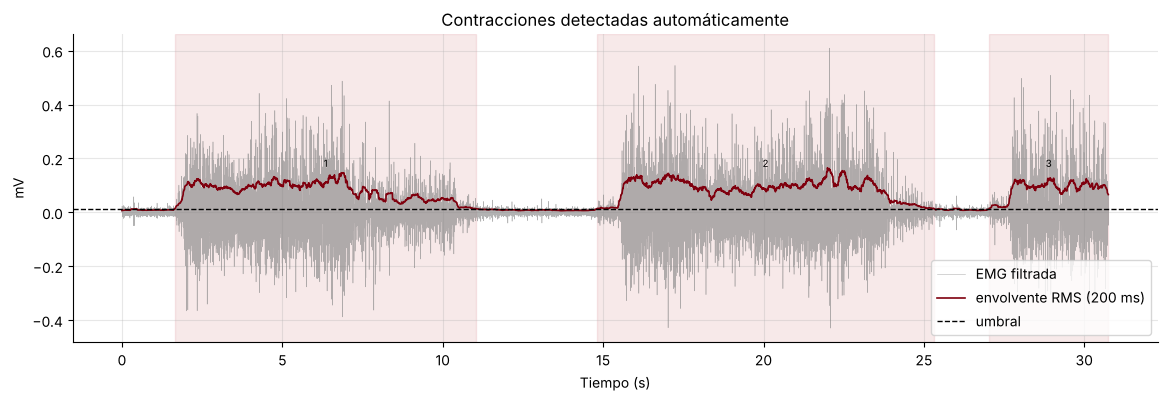

In [8]:
# DETECCIÓN DE CONTRACCIONES DEL GASTROCNEMIO

def envolvente_rms(x, fs=FS, ventana_ms=200):
    w = max(1, int(fs * ventana_ms / 1000))
    # RMS móvil: raíz de la media móvil de x² → envolvente suave de la actividad del músculo
    return np.sqrt(np.convolve(x**2, np.ones(w)/w, mode="same"))

env_base   = envolvente_rms(emg_base_f)
env_prueba = envolvente_rms(emg_prueba_f)

K = 5

# Umbral con reposo dentro de la misma prueba: se usa el 20 % más bajo de la envolvente
ref = env_prueba[env_prueba <= np.percentile(env_prueba, 20)]
umbral = ref.mean() + K * ref.std()

print(f"Umbral con reposo intra-registro: {umbral*1000:.1f} µV")

# hueco_min_s baja de 1 s a 0.5 s: con 1 s la 2.ª y la 3.ª contracción del gastrocnemio se unían en una sola
def limpiar_mascara(activo, fs=FS, hueco_min_s=0.5, dur_min_s=0.50):
    # Junta segmentos separados por pausas cortas y descarta activaciones muy breves
    d = np.diff(np.r_[0, activo.astype(int), 0])
    inicios, fines = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    segs = []
    for s, e in zip(inicios, fines):
        if segs and s - segs[-1][1] < hueco_min_s * fs:
            segs[-1] = (segs[-1][0], e)
        else:
            segs.append((s, e))
    segs = [(s, e) for s, e in segs if (e - s) >= dur_min_s * fs]
    mascara = np.zeros(len(activo), dtype=bool)
    for s, e in segs:
        mascara[s:e] = True
    return mascara, segs

mascara_activa, contracciones = limpiar_mascara(env_prueba > umbral)
dur = np.array([(e - s) / FS for s, e in contracciones])
print(f"Contracciones detectadas: {len(contracciones)} | duración media {dur.mean():.2f} ± {dur.std():.2f} s")

plt.figure(figsize=(14, 4))
plt.plot(t_prueba, emg_prueba_f, lw=0.4, color="gray", alpha=0.6, label="EMG filtrada")
plt.plot(t_prueba, env_prueba, lw=1.2, color=COLOR_UPCH, label="envolvente RMS (200 ms)")
plt.axhline(umbral, color="k", ls="--", lw=1, label="umbral")
for i, (s, e) in enumerate(contracciones):
    plt.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.12)
    plt.text((s+e)/2/FS, env_prueba.max()*1.02, str(i+1), ha="center", fontsize=7)
plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.title("Contracciones detectadas automáticamente")
plt.legend(loc="lower right"); plt.show()

In [9]:
# VENTANEO Y ETIQUETADO DE CADA VENTANA

def crear_ventanas(x, fs=FS, ventana_ms=250, solapamiento=0.5):
    # Divide la señal en ventanas de ventana_ms con el solapamiento dado; devuelve las ventanas y sus inicios

    n = int(round(fs * ventana_ms / 1000))
    paso = max(1, int(round(n * (1 - solapamiento))))
    inicios = np.arange(0, len(x) - n + 1, paso)
    return np.stack([x[i:i+n] for i in inicios]), inicios

VENTANA_MS, SOLAP = 250, 0.5
ventanas, inicios = crear_ventanas(emg_prueba_f, FS, VENTANA_MS, SOLAP)
n_win = ventanas.shape[1]

# Para cada ventana: etiqueta, ciclo (grupo) y si tiene saturación
frac_activa = np.array([mascara_activa[i:i+n_win].mean() for i in inicios])
etiqueta = np.where(frac_activa >= 0.8, "contraccion", np.where(frac_activa <= 0.05, "reposo", "transicion"))

inicios_contr = np.array([s for s, _ in contracciones])
ciclo = np.searchsorted(inicios_contr, inicios + n_win // 2, side="right")
ciclo = np.where(etiqueta == "reposo", np.searchsorted(inicios_contr, inicios, side="left"), ciclo - 1)
ciclo = np.clip(ciclo, 0, len(contracciones) - 1)

ventana_saturada = np.array([sat_prueba[i:i+n_win].any() for i in inicios])

print(f"Ventanas: {len(ventanas)} de {n_win} muestras ({VENTANA_MS} ms, solapamiento {int(SOLAP*100)} %)")
print(pd.Series(etiqueta).value_counts().to_string())
print(f"Ventanas con al menos una muestra saturada: {ventana_saturada.sum()}")

Ventanas: 245 de 250 muestras (250 ms, solapamiento 50 %)
contraccion    185
reposo          52
transicion       8
Ventanas con al menos una muestra saturada: 0


CARACTERISTICAS CLÁSICAS

In [10]:
EPS = 3 * np.std(emg_base_f)   # umbral de ruido (3σ del baseline) para ZC, SSC y WAMP
print(f"Umbral de ruido ε = {EPS*1000:.1f} µV")

def caracteristicas_temporales(x, eps=EPS):
    dx = np.diff(x)
    zc   = np.sum((x[:-1] * x[1:] < 0) & (np.abs(dx) >= eps))
    ssc  = np.sum(((dx[:-1] * dx[1:]) < 0) & ((np.abs(dx[:-1]) >= eps) | (np.abs(dx[1:]) >= eps)))
    return {
        "MAV":  np.mean(np.abs(x)),
        "RMS":  np.sqrt(np.mean(x**2)),
        "iEMG": np.sum(np.abs(x)),
        "VAR":  np.var(x, ddof=1),
        "WL":   np.sum(np.abs(dx)),
        "ZC":   zc,
        "SSC":  ssc,
        "WAMP": np.sum(np.abs(dx) > eps),
        "Asimetria": skew(x),
        "Curtosis":  kurtosis(x, fisher=True, bias=False),
    }

def caracteristicas_frecuenciales(x, fs=FS):
    f, p = signal.welch(x, fs=fs, nperseg=min(128, len(x)))
    banda = (f >= 20) & (f <= 450)
    f, p = f[banda], p[banda]
    p_tot = p.sum()
    acum = np.cumsum(p)
    pot = lambda lo, hi: p[(f >= lo) & (f < hi)].sum() / p_tot
    return {
        "MNF": np.sum(f * p) / p_tot,
        "MDF": f[np.searchsorted(acum, acum[-1] / 2)],
        "P_20_80":   pot(20, 80),
        "P_80_150":  pot(80, 150),
        "P_150_450": pot(150, 451),
    }

def extraer_caracteristicas(x, fs=FS):
    c = caracteristicas_temporales(x)
    c.update(caracteristicas_frecuenciales(x, fs))
    return c

# Ejemplo con una ventana de reposo y una de contracción
i_rep = np.flatnonzero(etiqueta == "reposo")[3]
i_con = np.flatnonzero(etiqueta == "contraccion")[3]
display(pd.DataFrame({"reposo": extraer_caracteristicas(ventanas[i_rep]),
                      "contraccion": extraer_caracteristicas(ventanas[i_con])}).round(4))

Umbral de ruido ε = 11.0 µV


,reposo,contraccion
MAV,0.0072,0.0810
RMS,0.0098,0.1067
iEMG,1.8068,20.2599
VAR,0.0001,0.0114
WL,1.8630,13.5585
ZC,43.0000,43.0000
SSC,57.0000,82.0000
WAMP,61.0000,208.0000
Asimetria,-0.1752,0.0016
Curtosis,3.8897,0.9589


In [11]:
# MATRIZ DE CARACTERÍSTICAS (una fila por ventana)
df = pd.DataFrame([extraer_caracteristicas(w) for w in ventanas])
CARACTERISTICAS = list(df.columns)
df.insert(0, "t_inicio_s", inicios / FS)
df["etiqueta"] = etiqueta
df["ciclo"] = ciclo
df["saturada"] = ventana_saturada

print("Matriz de características:", df[CARACTERISTICAS].shape, "(ventanas × características)")
display(df.head())
display(df.groupby("etiqueta")[CARACTERISTICAS].mean().T.round(4))

Matriz de características: (245, 15) (ventanas × características)


,t_inicio_s,MAV,RMS,iEMG,VAR,WL,ZC,SSC,WAMP,Asimetria,Curtosis,MNF,MDF,P_20_80,P_80_150,P_150_450,etiqueta,ciclo,saturada
0,0.000,0.006725,0.008348,1.681348,0.000070,1.817450,51,71,66,0.195068,0.077682,181.846118,195.3125,0.294792,0.169321,0.535887,reposo,0,False
1,0.125,0.007043,0.010022,1.760796,0.000101,2.013137,52,63,70,0.273487,8.817145,168.818142,195.3125,0.254548,0.160314,0.585138,reposo,0,False
2,0.250,0.007489,0.011148,1.872132,0.000125,2.084975,49,63,72,-0.162328,7.422290,154.756517,132.8125,0.237500,0.399929,0.362571,reposo,0,False
3,0.375,0.007227,0.009839,1.806801,0.000097,1.863024,43,57,61,-0.175189,3.889735,158.042385,164.0625,0.322649,0.145011,0.532341,reposo,0,False
4,0.500,0.006791,0.008484,1.697772,0.000072,1.833975,49,51,60,0.448370,0.972236,179.124079,195.3125,0.119838,0.238326,0.641836,reposo,0,False


etiqueta,contraccion,reposo,transicion
MAV,0.0619,0.0065,0.0091
RMS,0.0847,0.0086,0.0124
iEMG,15.4820,1.6306,2.2686
VAR,0.0083,0.0001,0.0002
WL,9.5876,1.6662,2.0207
ZC,45.8703,33.7115,36.0000
SSC,66.7351,42.9038,48.2500
WAMP,181.3459,47.1923,64.5000
Asimetria,0.5401,0.1128,0.0404
Curtosis,2.0022,1.6552,2.3612


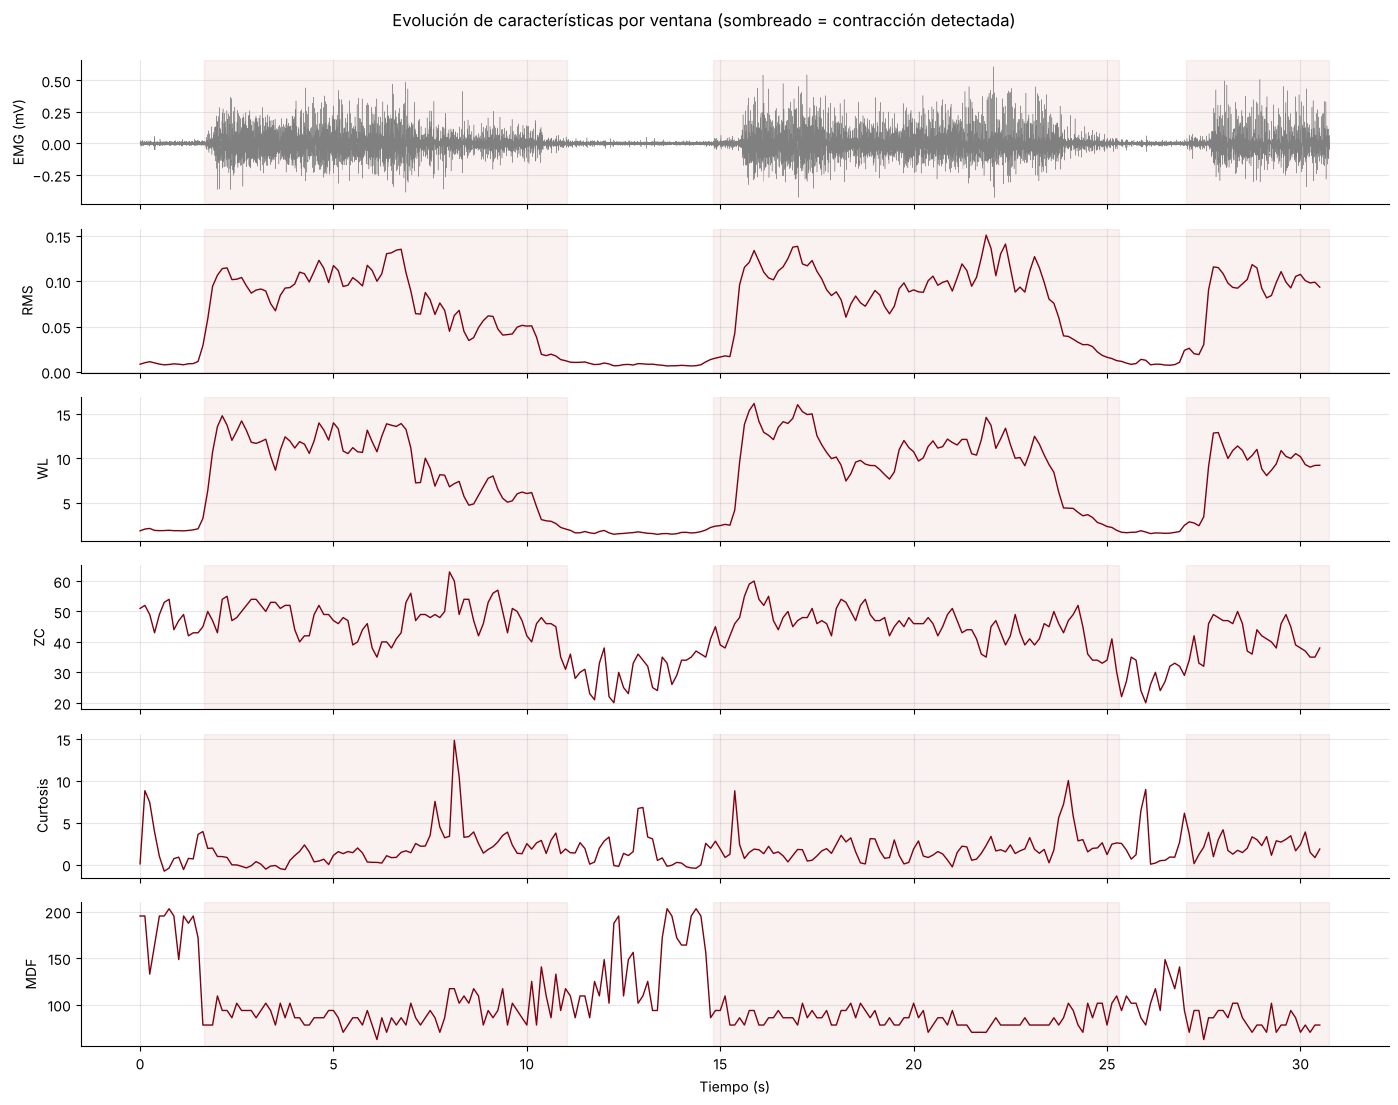

In [12]:
# EVOLUCIÓN TEMPORAL DE ALGUNAS CARACTERÍSTICAS
mostrar = ["RMS", "WL", "ZC", "Curtosis", "MDF"]
fig, ax = plt.subplots(len(mostrar) + 1, 1, figsize=(14, 11), sharex=True)
ax[0].plot(t_prueba, emg_prueba_f, lw=0.3, color="gray")
ax[0].set_ylabel("EMG (mV)")
for a, c in zip(ax[1:], mostrar):
    a.plot(df["t_inicio_s"], df[c], lw=1, color=COLOR_UPCH)
    a.set_ylabel(c)
for a in ax:
    for s, e in contracciones:
        a.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.08)
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("Evolución de características por ventana (sombreado = contracción detectada)", y=1.0)
plt.tight_layout(); plt.show()

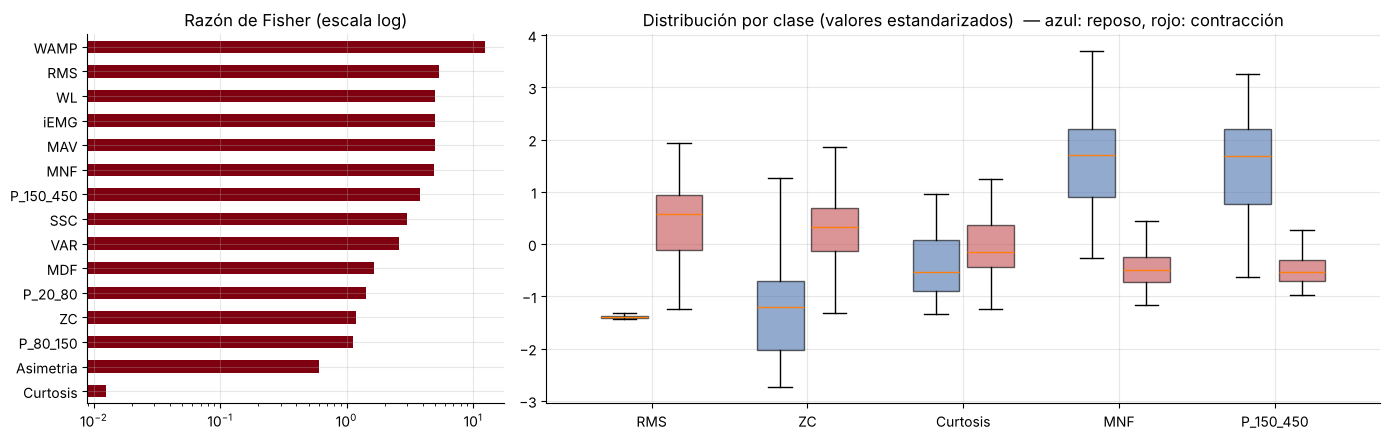

WAMP         12.49
RMS           5.35
WL            5.03
iEMG          4.99
MAV           4.99
MNF           4.95
P_150_450     3.81
SSC           3.03
VAR           2.60
MDF           1.63
P_20_80       1.43
ZC            1.20
P_80_150      1.11
Asimetria     0.60
Curtosis      0.01


In [13]:
# RAZÓN DE FISHER (cuánto separa cada característica reposo y contracción)

df_ml = df[df["etiqueta"] != "transicion"].copy()
r, c = df_ml[df_ml.etiqueta == "reposo"], df_ml[df_ml.etiqueta == "contraccion"]
fisher = ((r[CARACTERISTICAS].mean() - c[CARACTERISTICAS].mean())**2 /
          (r[CARACTERISTICAS].var() + c[CARACTERISTICAS].var())).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
fisher.plot.barh(ax=ax[0], color=COLOR_UPCH); ax[0].invert_yaxis()
ax[0].set_xscale("log"); ax[0].set_title("Razón de Fisher (escala log)")

seleccion = ["RMS", "ZC", "Curtosis", "MNF", "P_150_450"]
datos_z = (df_ml[seleccion] - df_ml[seleccion].mean()) / df_ml[seleccion].std()
pos = np.arange(len(seleccion))
for k, (lab, col) in enumerate([("reposo", COLOR_REPOSO), ("contraccion", COLOR_CONTRAC)]):
    bp = ax[1].boxplot([datos_z[df_ml.etiqueta == lab][s] for s in seleccion],
                       positions=pos + (k - 0.5) * 0.35, widths=0.3, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(col); b.set_alpha(0.6)
ax[1].set_xticks(pos); ax[1].set_xticklabels(seleccion)
ax[1].set_title("Distribución por clase (valores estandarizados)  — azul: reposo, rojo: contracción")
plt.tight_layout(); plt.show()
print(fisher.round(2).to_string())

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

# CLASIFICACIÓN CLÁSICA (LDA y SVM) VALIDANDO POR GRUPOS

# Nota: iEMG = n·MAV y P_80_150 = 1 − P_20_80 − P_150_450 son combinaciones lineales de otras columnas,
# por eso el LDA puede mostrar el aviso "Variables are collinear"

X = df_ml[CARACTERISTICAS].values
y = (df_ml["etiqueta"] == "contraccion").astype(int).values
grupos = df_ml["ciclo"].values

modelos = {
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
}
conjuntos = {
    "Todas las características": CARACTERISTICAS,
    "Solo amplitud (RMS)": ["RMS"],
    "Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)":
        ["Curtosis", "Asimetria", "MNF", "MDF", "P_20_80", "P_80_150", "P_150_450"],
}

# El número de pliegues no puede superar el número de grupos (contracciones detectadas)
N_PLIEGUES = min(5, len(np.unique(grupos)))
print(f"Grupos: {len(np.unique(grupos))} → GroupKFold con {N_PLIEGUES} pliegues")
cv_grupos = GroupKFold(n_splits=N_PLIEGUES)
filas = []
for nombre_conj, cols in conjuntos.items():
    Xc = df_ml[cols].values
    for nombre_mod, mod in modelos.items():
        s = cross_val_score(mod, Xc, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
        filas.append({"Características": nombre_conj, "Modelo": nombre_mod,
                      "Exactitud balanceada": f"{s.mean():.3f} ± {s.std():.3f}"})
display(pd.DataFrame(filas))

Grupos: 3 → GroupKFold con 3 pliegues


,Características,Modelo,Exactitud balanceada
0,Todas las características,LDA,1.000 ± 0.000
1,Todas las características,SVM-RBF,0.984 ± 0.018
2,Solo amplitud (RMS),LDA,0.937 ± 0.019
3,Solo amplitud (RMS),SVM-RBF,0.983 ± 0.015
4,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",LDA,0.911 ± 0.039
5,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",SVM-RBF,0.889 ± 0.052


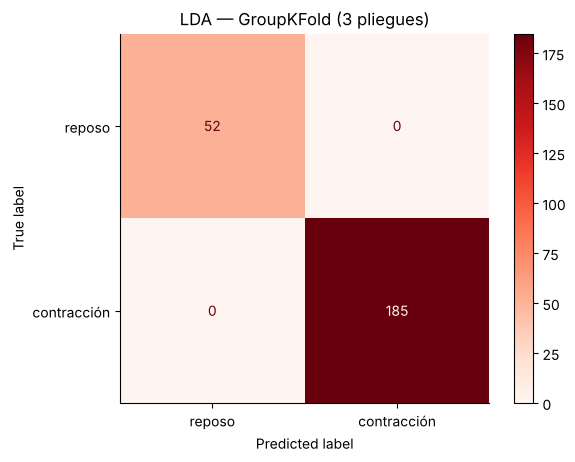

SVM sin amplitud — KFold aleatorio (con fuga): 0.902
SVM sin amplitud — GroupKFold (sin fuga)    : 0.889


In [15]:
# MATRIZ DE CONFUSIÓN (LDA con todas las características, validación por grupos)
y_pred = cross_val_predict(modelos["LDA"], X, y, cv=cv_grupos, groups=grupos)
ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=["reposo", "contracción"]).plot(cmap="Reds")
plt.title(f"LDA — GroupKFold ({N_PLIEGUES} pliegues)"); plt.grid(False); plt.show()

# Fuga de datos: KFold aleatorio vs GroupKFold usando solo características SIN amplitud
cols_dificil = conjuntos["Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)"]
Xd = df_ml[cols_dificil].values
mod = modelos["SVM-RBF"]
s_kf = cross_val_score(mod, Xd, y, cv=KFold(5, shuffle=True, random_state=0), scoring="balanced_accuracy")
s_gk = cross_val_score(mod, Xd, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"SVM sin amplitud — KFold aleatorio (con fuga): {s_kf.mean():.3f}")
print(f"SVM sin amplitud — GroupKFold (sin fuga)    : {s_gk.mean():.3f}")

In [16]:
# VERIFICACIÓN ADICIONAL (preguntas del bloque 6)
from sklearn.tree import DecisionTreeClassifier

# (a) ¿Alcanza con un solo umbral en RMS? Un árbol de profundidad 1 aprende un único umbral
arbol = DecisionTreeClassifier(max_depth=1, random_state=0)
s_umbral = cross_val_score(arbol, df_ml[["RMS"]].values, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"Un solo umbral en RMS (GroupKFold): {s_umbral.mean():.3f} ± {s_umbral.std():.3f}")

# (b) LDA con RMS y con log(RMS)
s_lin = cross_val_score(modelos["LDA"], df_ml[["RMS"]].values, y, cv=cv_grupos, groups=grupos,
                        scoring="balanced_accuracy")
s_log = cross_val_score(modelos["LDA"], np.log(df_ml[["RMS"]].values), y, cv=cv_grupos, groups=grupos,
                        scoring="balanced_accuracy")
print(f"LDA con RMS     : {s_lin.mean():.3f} ± {s_lin.std():.3f}")
print(f"LDA con log(RMS): {s_log.mean():.3f} ± {s_log.std():.3f}")

# (c) Media, dispersión y asimetría del RMS en cada clase
for lab in ["reposo", "contraccion"]:
    v = df_ml.loc[df_ml.etiqueta == lab, "RMS"]
    print(f"RMS en {lab:11s}: media {v.mean():.3f} mV | desv. est. {v.std():.3f} mV | asimetría {skew(v):.2f}")

Un solo umbral en RMS (GroupKFold): 0.984 ± 0.018


LDA con RMS     : 0.937 ± 0.019
LDA con log(RMS): 0.965 ± 0.006
RMS en reposo     : media 0.009 mV | desv. est. 0.002 mV | asimetría 1.12
RMS en contraccion: media 0.085 mV | desv. est. 0.033 mV | asimetría -0.59


Imágenes: (114, 27, 29) (muestras, frecuencias, tiempos) | reposo: 23  contracción: 91


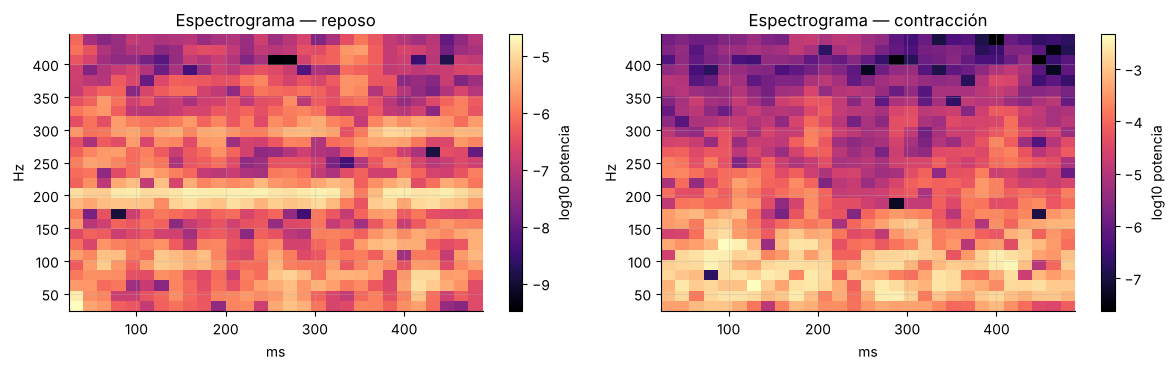

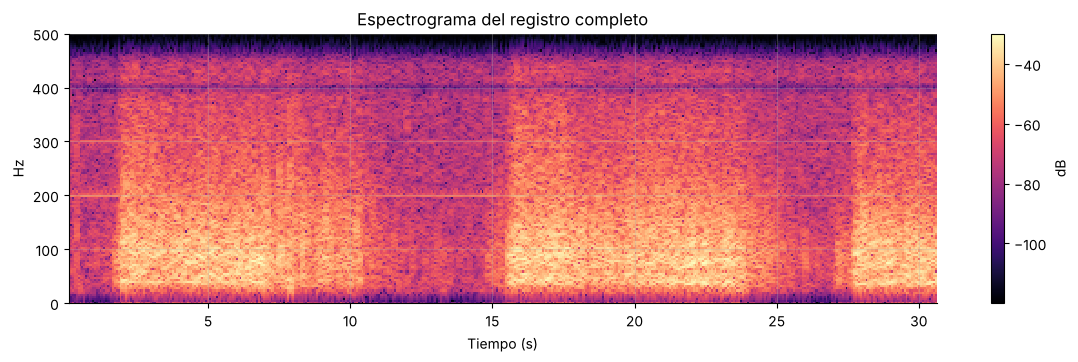

In [17]:
# ESPECTROGRAMAS PARA LA CNN
# Ventanas de 500 ms para que cada espectrograma tenga suficientes columnas de tiempo
VENTANA_CNN_MS = 500
win_cnn, ini_cnn = crear_ventanas(emg_prueba_f, FS, VENTANA_CNN_MS, 0.5)
n_cnn = win_cnn.shape[1]
frac = np.array([mascara_activa[i:i+n_cnn].mean() for i in ini_cnn])
lab_cnn = np.where(frac >= 0.8, 1, np.where(frac <= 0.05, 0, -1))
ciclo_cnn = np.clip(np.where(lab_cnn == 0,
                             np.searchsorted(inicios_contr, ini_cnn, side="left"),
                             np.searchsorted(inicios_contr, ini_cnn + n_cnn//2, side="right") - 1),
                    0, len(contracciones) - 1)
ok = lab_cnn >= 0
win_cnn, lab_cnn, ciclo_cnn = win_cnn[ok], lab_cnn[ok], ciclo_cnn[ok]

def espectrograma(x, fs=FS, nperseg=64, noverlap=48):
    f, t, S = signal.stft(x, fs=fs, nperseg=nperseg, noverlap=noverlap, boundary=None)
    banda = (f >= 20) & (f <= 450)
    return f[banda], t, np.log10(np.abs(S[banda])**2 + 1e-10)

f_s, t_s, _ = espectrograma(win_cnn[0])
imagenes = np.stack([espectrograma(w)[2] for w in win_cnn]).astype(np.float32)
print(f"Imágenes: {imagenes.shape} (muestras, frecuencias, tiempos) | "
      f"reposo: {(lab_cnn==0).sum()}  contracción: {(lab_cnn==1).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, clase, nombre in zip(ax, [0, 1], ["reposo", "contracción"]):
    i = np.flatnonzero(lab_cnn == clase)[2]
    im = a.pcolormesh(t_s*1000, f_s, imagenes[i], shading="auto", cmap="magma")
    a.set_title(f"Espectrograma — {nombre}"); a.set_xlabel("ms"); a.set_ylabel("Hz")
    plt.colorbar(im, ax=a, label="log10 potencia")
plt.tight_layout(); plt.show()

# Espectrograma de toda la prueba: cómo cambia el contenido en frecuencia a lo largo del tiempo
f_full, t_full, S_full = signal.spectrogram(emg_prueba_f, fs=FS, nperseg=256, noverlap=192)
plt.figure(figsize=(14, 3.5))
plt.pcolormesh(t_full, f_full, 10*np.log10(S_full + 1e-12), shading="auto", cmap="magma")
plt.ylim(0, 500); plt.xlabel("Tiempo (s)"); plt.ylabel("Hz"); plt.colorbar(label="dB")
plt.title("Espectrograma del registro completo"); plt.show()

In [18]:
# DEFINICIÓN DE LA CNN
try:
    import torch
    import torch.nn as nn
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
    print("PyTorch no está disponible. En Colab viene preinstalado; localmente: pip install torch")

if TORCH_OK:
    torch.manual_seed(0)

    class CNNEspectrograma(nn.Module):
        def __init__(self, n_clases=2):
            super().__init__()
            self.extractor = nn.Sequential(
                nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                nn.AdaptiveAvgPool2d(1),
            )
            self.clasificador = nn.Linear(16, n_clases)
        def forward(self, x):
            return self.clasificador(self.extractor(x).flatten(1))

    def entrenar_cnn(X_tr, y_tr, X_te, epocas=40, lr=1e-2):
        mu, sd = X_tr.mean(), X_tr.std()
        Xtr = torch.tensor((X_tr - mu) / sd).unsqueeze(1)
        Xte = torch.tensor((X_te - mu) / sd).unsqueeze(1)
        ytr = torch.tensor(y_tr, dtype=torch.long)
        modelo = CNNEspectrograma()
        opt = torch.optim.Adam(modelo.parameters(), lr=lr)
        perdida_fn = nn.CrossEntropyLoss()
        historial = []
        for _ in range(epocas):
            modelo.train()
            perm = torch.randperm(len(Xtr))
            for i in range(0, len(Xtr), 32):
                idx = perm[i:i+32]
                if len(idx) < 2:      # BatchNorm necesita al menos 2 muestras por lote
                    continue
                opt.zero_grad()
                loss = perdida_fn(modelo(Xtr[idx]), ytr[idx])
                loss.backward(); opt.step()
            historial.append(loss.item())
        modelo.eval()
        with torch.no_grad():
            pred = modelo(Xte).argmax(1).numpy()
        return pred, historial, modelo

    print("Parámetros entrenables:",
          sum(p.numel() for p in CNNEspectrograma().parameters() if p.requires_grad))

Parámetros entrenables: 1330


Pliegue 1: exactitud balanceada = 1.000


Pliegue 2: exactitud balanceada = 0.986


Pliegue 3: exactitud balanceada = 1.000

CNN (espectrograma) — GroupKFold: 0.995 ± 0.007


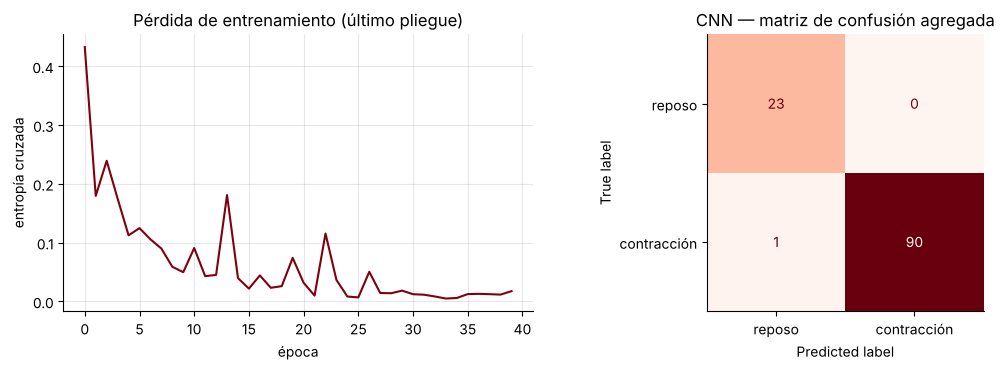

In [19]:
# ENTRENAMIENTO Y EVALUACIÓN DE LA CNN
if TORCH_OK:
    resultados_cnn, y_true_all, y_pred_all = [], [], []
    # Mismo criterio: tantos pliegues como grupos haya (máximo 5)
    n_pl_cnn = min(5, len(np.unique(ciclo_cnn)))
    for k, (tr, te) in enumerate(GroupKFold(n_splits=n_pl_cnn).split(imagenes, lab_cnn, ciclo_cnn)):
        pred, hist, modelo_cnn = entrenar_cnn(imagenes[tr], lab_cnn[tr], imagenes[te])
        resultados_cnn.append(balanced_accuracy_score(lab_cnn[te], pred))
        y_true_all += list(lab_cnn[te]); y_pred_all += list(pred)
        print(f"Pliegue {k+1}: exactitud balanceada = {resultados_cnn[-1]:.3f}")
    print(f"\nCNN (espectrograma) — GroupKFold: {np.mean(resultados_cnn):.3f} ± {np.std(resultados_cnn):.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist, color=COLOR_UPCH); ax[0].set_title("Pérdida de entrenamiento (último pliegue)")
    ax[0].set_xlabel("época"); ax[0].set_ylabel("entropía cruzada")
    ConfusionMatrixDisplay(confusion_matrix(y_true_all, y_pred_all),
                           display_labels=["reposo", "contracción"]).plot(ax=ax[1], cmap="Reds", colorbar=False)
    ax[1].grid(False); ax[1].set_title("CNN — matriz de confusión agregada")
    plt.tight_layout(); plt.show()

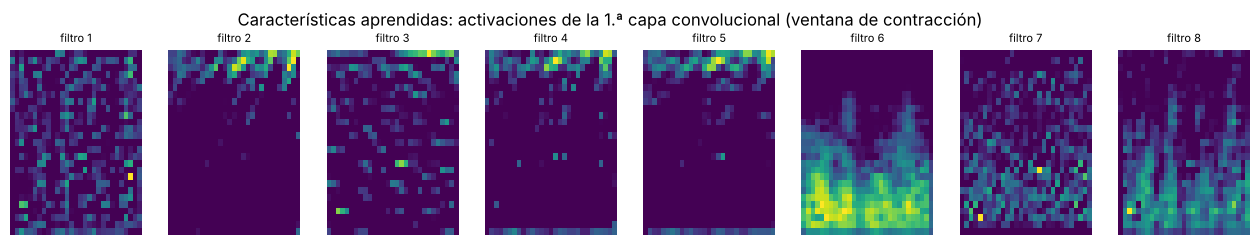

In [20]:
# MAPAS DE ACTIVACIÓN DE LOS 8 FILTROS DE LA PRIMERA CAPA
if TORCH_OK:
    i = np.flatnonzero(lab_cnn == 1)[2]
    x_in = torch.tensor((imagenes[i] - imagenes.mean()) / imagenes.std()).unsqueeze(0).unsqueeze(0)
    with torch.no_grad():
        mapas = modelo_cnn.extractor[:3](x_in)[0].numpy()
    fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
    for k in range(8):
        ax[k].imshow(mapas[k], origin="lower", aspect="auto", cmap="viridis")
        ax[k].set_title(f"filtro {k+1}", fontsize=8); ax[k].axis("off")
    plt.suptitle("Características aprendidas: activaciones de la 1.ª capa convolucional (ventana de contracción)", y=1.05)
    plt.show()